# 講義資料：膜反応器（TMR）のシミュレーションと性能評価


---

## 1. 膜反応器（Membrane Reactor）とは？

従来のプロセスでは、「反応器（Reactor）」で反応を行った後、後段の「分離装置（Separator）」で目的物を回収し、未反応原料をリサイクルしていました。
これに対し、**膜反応器**は「反応」と「分離」の機能を1つの装置に一体化（統合）させたシステムです。反応器の壁面などに特定物質を選択的に透過させる「分離膜」を配置し、反応の進行と同時に生成物を系外へ抜き取ります。


## 2.メンブレンリアクター概説
<figure style="text-align:center;">
<img
src="https://raw.githubusercontent.com/myokota812/lecture/master/AdvChE/figure/MembraneReactor.png"
width="600">
</figure>



この図は、反応器のチューブ内部で触媒反応を起こしながら、目的とする生成物を「選択的分離膜（Selective Membrane Layer）」を通して外側へ連続的に抜き取るシステムを表しています。

---

### 各部の詳細説明

1. **FEED INLET（原料供給口）**
* 原料となる成分（ここでは反応物 A など）が反応管（Reaction Tube）の内部へ流入する入口です。




2. **REACTION TUBE & CATALYST BED（反応管・触媒層）**
* 管の内部には触媒が充填されており、ここで逐次反応（$A \to B \to C$ など）が進行します。




3. **SELECTIVE MEMBRANE LAYER（選択的分離膜）**
* 反応管の内壁（または管壁自体）にコーティングされた膜です。


* 目的生成物（今回のテーマであれば物質 B）だけを選択的に透過させ、不要な成分や未反応物は通さない性質を持ちます。




4. **RETENTATE CHANNEL / OUTLET（透過しなかった流体の流れ）**
* 膜を通り抜けずに反応管の中をそのまま通り抜けた成分（未反応の A や、副生物の C など）が排出される出口です。


* 数値解析の物質収支では、出口側の流量（$F_{A3}, F_{C3}$ など）に相当します。


5. **PERMEATE CHANNEL / OUTLET（透過流体の流れ）**
* 膜を通り抜けて外側のシェル（外殻）側に抽出された目的生成物（B）が回収される出口です。


* 反応器の途中で B が系外へ引き抜かれるため、管内の B の濃度が低く抑えられ、副反応（$B \to C$）の進行を防ぐことができます。


6. **SWEEP GAS（スイープガス）**
* 必要に応じて外側シェル側に流すキャリアガス（$N_2$ など）です。膜を透過した生成物を速やかに押し流すことで、膜を挟んだ内外の濃度差（駆動力）を維持し、分離効率を高める役割を持ちます。





---



###  3. 膜反応器における物質収支と設計式（理論）

微小な反応体積要素 $dV$ における、各成分（$A, B, C$）の物質収支式を立てます。膜を透過して系外へ抜き取られる物質を考慮するのがポイントです。

#### ① 反応物 A の収支

Aは反応で消費されるのみで、膜を透過しないと仮定します。


$$\frac{dF_A}{dV} = -r_A = -k_1 C_A$$


（※ $F_A$：モル流量，$V$：反応体積，$C_A$：濃度，$r_A$：反応速度）

#### ② 目的物質 B の収支（重要）

Bは $A \to B$ で生成し、 $B \to C$ で消費されるだけでなく、**膜を通じて外へ透過・抜出**されます。


$$\frac{dF_B}{dV} = r_A - r_B - \text{(単位体積あたりの膜透過・抜出速度)}$$


ここで、反応速度は $r_A = k_1 C_A$、$r_B = k_2 C_B$ です。また、膜を通した透過速度は「膜の透過係数 $K_m$」と「単位体積あたりの膜面積 $a$」および濃度差に比例するため、次のように表されます。


$$\frac{dF_B}{dV} = k_1 C_A - k_2 C_B - K_m a (C_B - C_{B,\text{sweep}})$$


（※ $C_{B,\text{sweep}}$ はスイープガス側のBの濃度ですが、完全に除去する場合は $0$ と近似できます）

#### ③ 副生物 C の収支

Cは $B \to C$ で生成し、膜を透過しないと仮定します。


$$\frac{dF_C}{dV} = r_B = k_2 C_B$$

---

#### ④ 膜を透過した成分 B の累積量（Cumulative B Permeated）

* **物理的意味**：反応器の入口（$V = 0$）から任意の反応体積 $V$ に至るまでに、「分離膜を通り抜けて反応管の外側へ回収された成分 B の総量（モル流量）」を意味します。
* **数学的定義（微分方程式）**：
微小な体積要素 $dV$ の間で膜を透過する量 $[K_m a C_B \, dV]$ を、入口から体積 $V$ まで累積（積分）していくため、以下の微分方程式として組み込みます。

$$\frac{dF_{B,\text{perm}}}{dV} = K_m a C_B$$



（※ Python等のプログラムで計算する際は、濃度 $C_B$ をモル流量 $F_B$ と体積・流速の関係に置き換えて $K_m F_B$ のように表現することも一般的です）

---

#### ⑤ Total Yield（総収率）の定義

従来のPFRや単パスの系では、「反応器の出口に残っているB」だけで収率を計算していましたが、膜反応器では「反応管の中に残っているB（Retentate）」**と**「すでに膜を透過して外に回収されたB（Permeate）」**の**両方が製品として手に入ります。

そのため、真のパフォーマンスを評価するための **Total Yield（総収率）** は、これら2つを足し合わせて以下のように定義されます。


$$\text{Total Yield of B} = \frac{(\text{管内に残るB} : F_B) + (\text{外に回収されたBの累計} : F_{B,\text{perm}})}{F_{A0}}$$

---



## 4. なぜ膜反応器で収率が改善されるのか？（理論的考察）

1. **化学平衡の移動（ルシャトリエの法則）**
* 可逆反応の場合、生成物を系外に抜くことで平衡が右（生成系）に大きく傾き、転化率が劇的に向上します。


2. **逐次反応における「選択率」の向上**
* 通常のPFRでは、反応器内が進むにつれて $C_B$ が高くなり、結果として $B \to C$ の副反応速度（$r_C = k_2 C_B$）が速くなってしまいます。
* 膜反応器では、生成した先から $\text{B}$ を抜き取るため、反応器内の $C_B$ を低く抑えることができます。これにより**副反応（$B \to C$）の発生確率を大幅に下げ、$\text{B}$ の選択率と最大収率を限界以上に高める**ことができます。


## 5. 実装コード（Python）

以下のスクリプトを実行することで、膜反応器内のモル流量の変化、累積膜透過量、および「真の総収率」を計算し、ダブルY軸のグラフで可視化することができます。

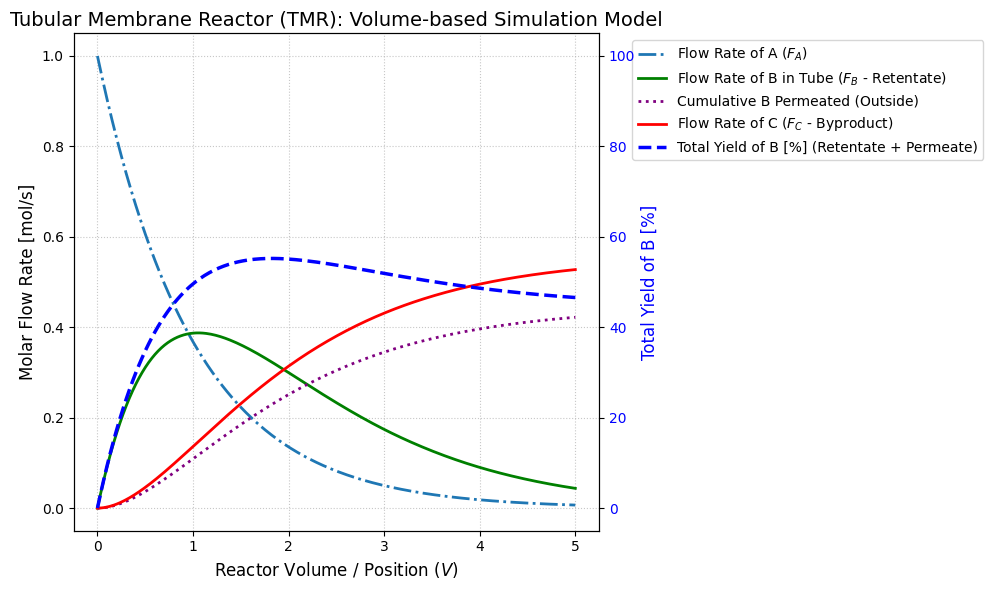

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp

# ============================================================
# 1. パラメータの設定（反応体積 V 基準）
# ============================================================
k1 = 1.0  # A → B の反応速度定数 [1/s]
k2 = 0.5  # B → C の反応速度定数 [1/s]
Km_a = 0.4  # 単位体積あたりの膜透過係数 (Km * a) [1/s] （※ 0にすると通常のPFRになる）

F_A0 = 1.0  # 入口の原料Aのモル流量 [mol/s]

# 反応体積 V の範囲 (zの代わりに体積 V を積分区間にする)
V_span = (0.0, 5.0)
V_eval = np.linspace(0.0, 5.0, 300)


# ============================================================
# 2. 膜反応器の微分方程式モデル（反応体積 V 基準で完全統一）
# ============================================================
def membrane_reactor_volume(V, F):
  FA, FB, FC, FB_perm_cum = F

  # 物質収支式（単位反応体積 V あたりの変化）
  dFA_dV = -k1 * FA
  dFB_dV = k1 * FA - k2 * FB - Km_a * FB  # 管内のBの変化（膜透過による抜出を含む）
  dFC_dV = k2 * FB

  # 膜を透過して外に出たBの累積（Cumulative B Permeated）の微分
  dFB_perm_cum_dV = Km_a * FB

  return [dFA_dV, dFB_dV, dFC_dV, dFB_perm_cum_dV]


# 初期条件 (V = 0 で Aのみ存在)
F0 = [F_A0, 0.0, 0.0, 0.0]

# 常微分方程式の数値解法 (Runge-Kutta法: RK45)
sol = solve_ivp(
    membrane_reactor_volume, V_span, F0, t_eval=V_eval, method='RK45'
)

# 結果の取得
V = sol.t
FA = sol.y[0]
FB_retentate = sol.y[1]  # 管内に残ったB (Retentate)
FC = sol.y[2]
FB_perm_cum = sol.y[3]  # 外側に回収されたBの累計 (Cumulative B Permeated)

# --- 総収率 (Total Yield) の計算 ---
Yield_Retentate = FB_retentate / F_A0
Yield_Permeate = FB_perm_cum / F_A0
Total_Yield_B = Yield_Retentate + Yield_Permeate  # 「管内」＋「外部回収」の総収率


# ============================================================
# 3. グラフ描画（ダブルY軸による可視化）
# ============================================================
fig, ax1 = plt.subplots(figsize=(10, 6))

# --- 左軸：モル流量・累積透過量 (Flow Rate & Cumulative Permeate) ---
ax1.plot(
    V, FA, label='Flow Rate of A ($F_A$)', linewidth=2, linestyle='-.', color='C0'
)
ax1.plot(
    V,
    FB_retentate,
    label='Flow Rate of B in Tube ($F_B$ - Retentate)',
    linewidth=2,
    color='g',
)
ax1.plot(
    V,
    FB_perm_cum,
    label='Cumulative B Permeated (Outside)',
    linewidth=2,
    color='purple',
    linestyle=':',
)
ax1.plot(
    V, FC, label='Flow Rate of C ($F_C$ - Byproduct)', linewidth=2, color='r'
)

ax1.set_xlabel('Reactor Volume / Position ($V$)', fontsize=12)
ax1.set_ylabel('Molar Flow Rate [mol/s]', fontsize=12)
ax1.set_ylim(-0.05, 1.05)

# --- 右軸：総収率 (Total Yield) ---
ax2 = ax1.twinx()
ax2.plot(
    V,
    Total_Yield_B * 100,
    label='Total Yield of B [%] (Retentate + Permeate)',
    linewidth=2.5,
    linestyle='--',
    color='b',
)
ax2.set_ylabel('Total Yield of B [%]', fontsize=12, color='b')
ax2.tick_params(axis='y', labelcolor='b')
ax2.set_ylim(-5, 105)

# --- 凡例とレイアウトの調整 ---
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
# --- 凡例をグラフの右外側に配置する場合 ---
ax1.legend(
    lines_1 + lines_2,
    labels_1 + labels_2,
    fontsize=10,
    loc='upper left',
    bbox_to_anchor=(1.05, 1),  # 右外側に配置
)
# 右側にスペースを作ることで凡例が切れるのを防ぐ
plt.subplots_adjust(right=0.75)

plt.title(
    'Tubular Membrane Reactor (TMR): Volume-based Simulation Model', fontsize=14
)
ax1.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp

# ============================================================
# 1. パラメータの設定
# ============================================================
k1 = 1.0  # A → B の反応速度定数 [1/s]
k2 = 0.5  # B → C の反応速度定数 [1/s]
Km = 0.4  # Bの膜透過（抜出）係数 （※ 0にすると通常のPFRになる）

F_A0 = 1.0  # 入口の原料Aのモル流量 [mol/s]

# 管の長さ（空間変数の範囲）
z_span = (0.0, 5.0)
z_eval = np.linspace(0.0, 5.0, 300)


# ============================================================
# 2. 膜反応器の微分方程式モデル
# ============================================================
def membrane_reactor(z, F):
  FA, FB, FC, FB_perm_cum = F

  # 物質収支式
  dFA_dz = -k1 * FA
  dFB_dz = k1 * FA - k2 * FB - Km * FB  # 管内のBの変化（膜透過による抜出を含む）
  dFC_dz = k2 * FB

  # 膜を透過して外に出たBの微分（Cumulative B Permeated の計算）
  dFB_perm_cum_dz = Km * FB

  return [dFA_dz, dFB_dz, dFC_dz, dFB_perm_cum_dz]


# 初期条件 (z=0 で Aのみ存在)
F0 = [F_A0, 0.0, 0.0, 0.0]

# 常微分方程式の数値解法 (Runge-Kutta法: RK45)
sol = solve_ivp(
    membrane_reactor, z_span, F0, t_eval=z_eval, method='RK45'
)

# 結果の取得
z = sol.t
FA = sol.y[0]
FB_retentate = sol.y[1]  # 管内に残ったB (Retentate)
FC = sol.y[2]
FB_perm_cum = sol.y[3]  # 外側に回収されたBの累計 (Cumulative B Permeated)

# --- 総収率 (Total Yield) の計算 ---
Yield_Retentate = FB_retentate / F_A0
Yield_Permeate = FB_perm_cum / F_A0
Total_Yield_B = Yield_Retentate + Yield_Permeate  # 「管内」＋「外部回収」の総収率


# ============================================================
# 3. グラフ描画（ダブルY軸による可視化）
# ============================================================
fig, ax1 = plt.subplots(figsize=(10, 6))

# --- 左軸：モル流量・累積透過量 (Flow Rate & Cumulative Permeate) ---
ax1.plot(
    z, FA, label='Flow Rate of A ($F_A$)', linewidth=2, linestyle='-.', color='C0'
)
ax1.plot(
    z,
    FB_retentate,
    label='Flow Rate of B in Tube ($F_B$ - Retentate)',
    linewidth=2,
    color='g',
)
ax1.plot(
    z,
    FB_perm_cum,
    label='Cumulative B Permeated (Outside)',
    linewidth=2,
    color='purple',
    linestyle=':',
)
ax1.plot(
    z, FC, label='Flow Rate of C ($F_C$ - Byproduct)', linewidth=2, color='r'
)

ax1.set_xlabel('Reactor Length / Position ($z$)', fontsize=12)
ax1.set_ylabel('Molar Flow Rate [mol/s]', fontsize=12)
ax1.set_ylim(-0.05, 1.05)

# --- 右軸：総収率 (Total Yield) ---
ax2 = ax1.twinx()
ax2.plot(
    z,
    Total_Yield_B * 100,
    label='Total Yield of B [%] (Retentate + Permeate)',
    linewidth=2.5,
    linestyle='--',
    color='b',
)
ax2.set_ylabel('Total Yield of B [%]', fontsize=12, color='b')
ax2.tick_params(axis='y', labelcolor='b')
ax2.set_ylim(-5, 105)

# --- 凡例とレイアウトの調整 ---
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(
    lines_1 + lines_2, labels_1 + labels_2, fontsize=10, loc='lower right'
)

plt.title(
    'Tubular Membrane Reactor (TMR): Retentate, Permeate & Total Yield',
    fontsize=14,
)
ax1.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()



---

## 5. 演習・考察課題

1. **プログラムの挙動確認**：
* コード内の `Km = 0.4` を `Km = 0.0`（通常のPFR）に変更して実行し、紫色で示される `Cumulative B Permeated` がどうなるか、またTotal Yieldの挙動が通常のPFRの限界値とどう一致するかを確認せよ。


2. **膜分離の効果の考察**：
* グラフ上で、反応管を進むにつれて紫色の線（Cumulative B Permeated）が増加していくことが、なぜ副生物 C の抑制（赤線の低減）につながるのか、物質収支の観点から説明せよ。

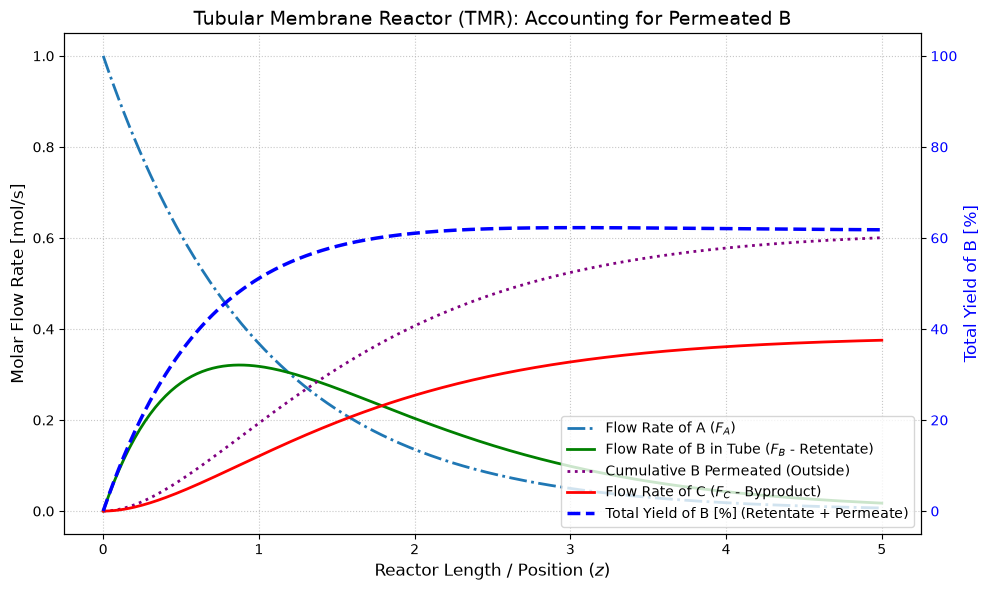

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp

# ============================================================
# 1. パラメータの設定
# ============================================================
k1 = 1.0  # A → B の反応速度定数
k2 = 0.5  # B → C の反応速度定数
Km = 0.8  # Bの膜透過（抜出）係数 （※0より大きくして効果を確認）

F_A0 = 1.0  # 入口の原料Aのモル流量

# 管の長さ（空間変数の範囲）
z_span = (0.0, 5.0)
z_eval = np.linspace(0.0, 5.0, 300)


# ============================================================
# 2. 膜反応器の微分方程式モデル（透過量の累積も追加）
# ============================================================
def membrane_reactor(z, F):
  FA, FB, FC, FB_perm_cum = F

  # 物質収支式
  dFA_dz = -k1 * FA
  dFB_dz = k1 * FA - k2 * FB - Km * FB  # 管内のBの変化
  dFC_dz = k2 * FB

  # 膜を透過して外に出たBの微分（累積用）
  dFB_perm_cum_dz = Km * FB

  return [dFA_dz, dFB_dz, dFC_dz, dFB_perm_cum_dz]


# 初期条件 (z=0 で Aのみ存在。透過累積も最初は0)
F0 = [F_A0, 0.0, 0.0, 0.0]

# 常微分方程式の数値解法
sol = solve_ivp(
    membrane_reactor, z_span, F0, t_eval=z_eval, method='RK45'
)

# 結果の取得
z = sol.t
FA = sol.y[0]
FB_retentate = sol.y[1]  # 管内に残ったB
FC = sol.y[2]
FB_perm_cum = sol.y[3]  # 膜を透過して外に回収されたBの累計

# --- 収率の計算 ---
# ① 管内に残っているBの収率
Yield_Retentate = FB_retentate / F_A0
# ② 膜を透過して外に回収されたBの収率
Yield_Permeate = FB_perm_cum / F_A0
# ③ 合計の「総収率」
Total_Yield_B = Yield_Retentate + Yield_Permeate


# ============================================================
# 3. グラフ描画（ダブルY軸）
# ============================================================
fig, ax1 = plt.subplots(figsize=(10, 6))

# --- 左軸：モル流量 (Flow Rate) ---
ax1.plot(
    z, FA, label='Flow Rate of A ($F_A$)', linewidth=2, linestyle='-.', color='C0'
)
ax1.plot(
    z,
    FB_retentate,
    label='Flow Rate of B in Tube ($F_B$ - Retentate)',
    linewidth=2,
    color='g',
)
ax1.plot(
    z,
    FB_perm_cum,
    label='Cumulative B Permeated (Outside)',
    linewidth=2,
    color='purple',
    linestyle=':',
)
ax1.plot(
    z, FC, label='Flow Rate of C ($F_C$ - Byproduct)', linewidth=2, color='r'
)

ax1.set_xlabel('Reactor Length / Position ($z$)', fontsize=12)
ax1.set_ylabel('Molar Flow Rate [mol/s]', fontsize=12)
ax1.set_ylim(-0.05, 1.05)

# --- 右軸：収率 (Yield) ---
ax2 = ax1.twinx()
ax2.plot(
    z,
    Total_Yield_B * 100,
    label='Total Yield of B [%] (Retentate + Permeate)',
    linewidth=2.5,
    linestyle='--',
    color='b',
)
ax2.set_ylabel('Total Yield of B [%]', fontsize=12, color='b')
ax2.tick_params(axis='y', labelcolor='b')
ax2.set_ylim(-5, 105)

# --- 凡例と装飾 ---
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(
    lines_1 + lines_2, labels_1 + labels_2, fontsize=10, loc='lower right'
)

plt.title(
    'Tubular Membrane Reactor (TMR): Accounting for Permeated B', fontsize=14
)
ax1.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

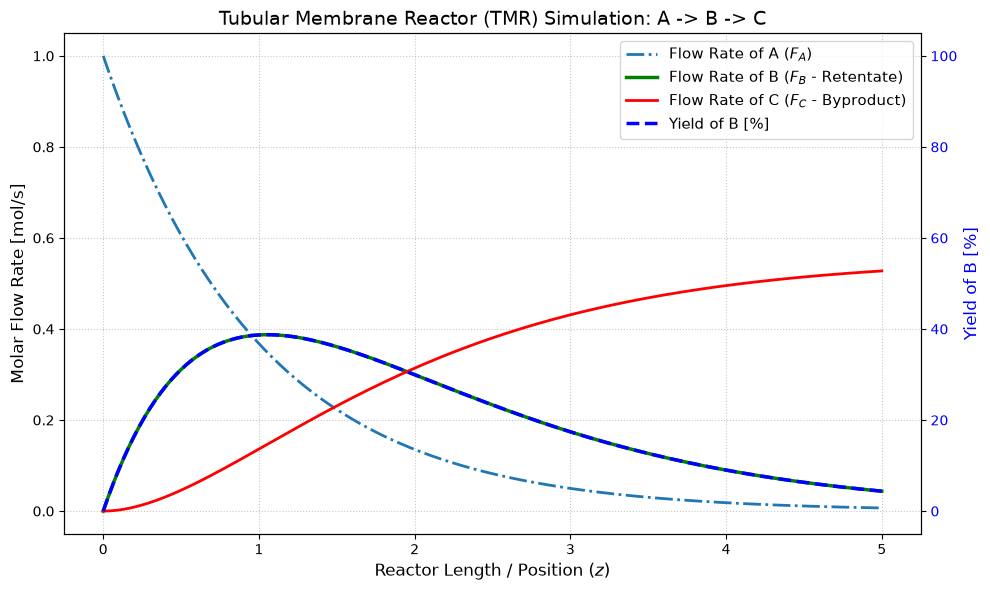

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp

# ============================================================
# 1. パラメータの設定
# ============================================================
k1 = 1.0  # A → B の反応速度定数
k2 = 0.5  # B → C の反応速度定数
Km = 0.4  # Bの膜透過（抜出）係数 （default 0.4, ※ 0にすると通常のPFRになる）

F_A0 = 1.0  # 入口の原料Aのモル流量

# 管の長さ（空間変数の範囲）
z_span = (0.0, 5.0)
z_eval = np.linspace(0.0, 5.0, 300)


# ============================================================
# 2. 膜反応器の微分方程式モデル
# ============================================================
def membrane_reactor(z, F):
  FA, FB, FC = F

  # 物質収支式
  dFA_dz = -k1 * FA
  dFB_dz = k1 * FA - k2 * FB - Km * FB  # 膜による抜出 (-Km * FB) を含む
  dFC_dz = k2 * FB

  return [dFA_dz, dFB_dz, dFC_dz]


# 初期条件 (z=0 で Aのみ存在)
F0 = [F_A0, 0.0, 0.0]

# 常微分方程式の数値解法 (Runge-Kutta法)
sol = solve_ivp(
    membrane_reactor, z_span, F0, t_eval=z_eval, method='RK45'
)

# 結果の取得
z = sol.t
FA = sol.y[0]
FB = sol.y[1]
FC = sol.y[2]

# 目的物質Bの収率（入口のAに対するBの割合）
Yield_B = FB / F_A0


# ============================================================
# 3. グラフ描画（ダブルY軸対応）
# ============================================================
fig, ax1 = plt.subplots(figsize=(10, 6))

# --- 左軸：モル流量 (Flow Rate) ---
ax1.plot(
    z, FA, label='Flow Rate of A ($F_A$)', linewidth=2, linestyle='-.', color='C0'
)
ax1.plot(
    z, FB, label='Flow Rate of B ($F_B$ - Retentate)', linewidth=2.5, color='g'
)
ax1.plot(
    z, FC, label='Flow Rate of C ($F_C$ - Byproduct)', linewidth=2, color='r'
)
ax1.set_xlabel('Reactor Length / Position ($z$)', fontsize=12)
ax1.set_ylabel('Molar Flow Rate [mol/s]', fontsize=12)
ax1.tick_params(axis='y')
ax1.set_ylim(-0.05, 1.05)

# --- 右軸：収率 (Yield) ---
ax2 = ax1.twinx()  # 共有するX軸に対して右側のY軸を追加
ax2.plot(
    z,
    Yield_B * 100,
    label='Yield of B [%]',
    linewidth=2.5,
    linestyle='--',
    color='b',
)
ax2.set_ylabel('Yield of B [%]', fontsize=12, color='b')
ax2.tick_params(axis='y', labelcolor='b')
ax2.set_ylim(-5, 105)

# --- 凡例を1つのボックスにまとめる ---
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(
    lines_1 + lines_2, labels_1 + labels_2, fontsize=11, loc='upper right'
)

# --- グラフ全体の装飾 ---
plt.title(
    'Tubular Membrane Reactor (TMR) Simulation: A -> B -> C', fontsize=14
)
ax1.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

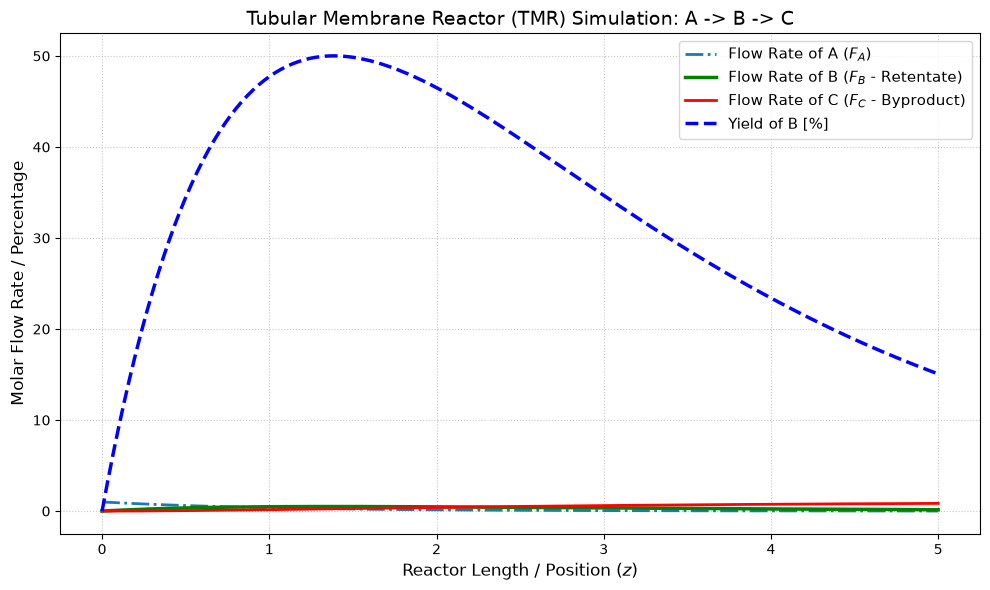

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp

# ============================================================
# 1. パラメータの設定
# ============================================================
k1 = 1.0  # A → B の反応速度定数
k2 = 0.5  # B → C の反応速度定数
Km = 0  # Bの膜透過（抜出）係数 （default 0.4, ※ 0にすると通常のPFRになる）

F_A0 = 1.0  # 入口の原料Aのモル流量

# 管の長さ（空間変数の範囲）
z_span = (0.0, 5.0)
z_eval = np.linspace(0.0, 5.0, 300)


# ============================================================
# 2. 膜反応器の微分方程式モデル
# ============================================================
def membrane_reactor(z, F):
  FA, FB, FC = F

  # 物質収支式
  dFA_dz = -k1 * FA
  dFB_dz = k1 * FA - k2 * FB - Km * FB  # 膜による抜出 (-Km * FB) を含む
  dFC_dz = k2 * FB

  return [dFA_dz, dFB_dz, dFC_dz]


# 初期条件 (z=0 で Aのみ存在)
F0 = [F_A0, 0.0, 0.0]

# 常微分方程式の数値解法 (Runge-Kutta法)
sol = solve_ivp(
    membrane_reactor, z_span, F0, t_eval=z_eval, method='RK45'
)

# 結果の取得
z = sol.t
FA = sol.y[0]
FB = sol.y[1]
FC = sol.y[2]

# 目的物質Bの収率（入口のAに対するBの割合）
# ※膜を透過して回収されたBの累積も考慮に入れる場合もありますが、
#   ここでは管内を流れるBおよび全体の生成挙動を評価します。
Yield_B = FB / F_A0


# ============================================================
# 3. グラフ描画
# ============================================================
plt.figure(figsize=(10, 6))

plt.plot(z, FA, label='Flow Rate of A ($F_A$)', linewidth=2, linestyle='-.')
plt.plot(
    z, FB, label='Flow Rate of B ($F_B$ - Retentate)', linewidth=2.5, color='g'
)
plt.plot(z, FC, label='Flow Rate of C ($F_C$ - Byproduct)', linewidth=2, color='r')
plt.plot(
    z,
    Yield_B * 100,
    label='Yield of B [%]',
    linewidth=2.5,
    linestyle='--',
    color='b',
)

plt.xlabel('Reactor Length / Position ($z$)', fontsize=12)
plt.ylabel('Molar Flow Rate / Percentage', fontsize=12)
plt.title(
    'Tubular Membrane Reactor (TMR) Simulation: A -> B -> C', fontsize=14
)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(fontsize=11, loc='upper right')
plt.tight_layout()
plt.show()